# Cost-Effectiveness — Spending and Coverage Gained in the 2014 Medicaid Expansion

**Artifact class:** `causal_analysis`  ·  **Data mode:** `empirical`  ·  **Vintage:** CMS-64 file of 2026-02-17 and ACS 2012–2019 1-year PUMS

This notebook uses **real data only**. There is no synthetic generator and no fallback. The effect comes from a
difference-in-differences on weighted PUMS cells (no person-level row is read, printed or stored); the cost comes from a
committed copy of the CMS file, checked against its recorded digest.

The analysis was fixed in a written plan (`pap/E01_plan.md`) committed after the CMS file was downloaded and its structure
(its columns and layout, not its amounts) inspected, and before the expenditure table was built or any expenditure amount was read. The notebook is bound to that file by its SHA-256 and says where it departs from it.

*Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

By the end of this notebook you will be able to:

1. **Define** a cost-effectiveness ratio as cost per unit of effect against a comparator, and say what the comparator is here
   (no expansion).
2. **Build** the numerator from a government expenditure file, with its negative adjustments, blanks and zeros read as they
   are and not repaired.
3. **Build** the denominator from a causal estimate, and see why the population the cost covers and the population the effect
   covers have to be the same.
4. **Propagate** uncertainty from the effect and from a range of costs into a ratio, and read a cost-effectiveness
   acceptability curve.
5. **State** which offsets the gross cost omits and in which direction that biases the ratio.

## Prerequisites

**Knowledge.** The difference-in-differences design of C01; what an incremental cost-effectiveness ratio is; weighted least squares.

**Setup.** A free Census API key from <https://api.census.gov/data/key_signup.html>, supplied by you as the environment variable
`CENSUS_API_KEY`, or as a line `CENSUS_API_KEY=...` in a file whose path you set in `KRL_SECRETS_PATH`. The key is read at
runtime and is never printed or written into this notebook's output. The retrieval makes 280 requests and takes several minutes.
The cost file is committed in the repository and needs no key.

**Packages.** `pandas`, `numpy`, `scipy`, `matplotlib`, `requests`, and the local `krl_tutorials_data` package (`methods.cea`
and `methods.iv`).

**Prior notebooks.** C01 supplies the design and the comparison estimate; C06 uses the same cells-only PUMS client; this notebook retrieves its own 280 requests.

## Data Provenance

| Item | Source | Role |
|---|---|---|
| `expansion_expenditure.csv` | CMS, *Medicaid CMS-64 New Adult Group Expenditures* (data.medicaid.gov), through `data/policy/medicaid/`; digest and transformation in its `SOURCES.md` | cost (numerator) |
| `HICOV`, `AGEP` | ACS 2012–2019 1-year PUMS, weighted cells only | newly insured persons (denominator) |
| `data/policy/medicaid/expansion_dates.csv` | KFF expansion status | treated and control states |
| C01's stored output | `projects/09-causal-identification/C01_medicaid_expansion_did/` | cross-check ATT, ages 35–64 |

Each PUMS request is recorded in `provenance/`, bound to the plan's SHA-256.

> **A mismatch that matters.** The CMS spending covers the whole expansion population, adults 19 to 64. C01's ATT is for ages
> 35 to 64 only, because the ACS table it uses has no consistent 19–64 series. Dividing a 19–64 cost by a 35–64 effect would
> overstate the cost per person, so the headline here applies C01's design to ages 19 to 64 (PUMS has single years of age, so
> there is no band change). C01's own ATT is shown beside it, and a second, labelled upper bound counts only the 35–64 effect.

## Design and identification

**Estimand.** Gross public spending per newly insured person-year, for the 25 states whose expansion took effect on 1 January 2014,
over 2014 to 2019, against no expansion. The comparator is the never-expanded states.

**Effect.** A difference-in-differences on the share of adults 19 to 64 with no health insurance, weighted by population, with state and year effects, clustered by
state. It is not C01's estimator: C01's headline is unweighted with a 2010-2013 baseline, a lead test and a wild bootstrap. This one corresponds to C01's weighted
sensitivity with a 2012-2013 pre-period; the labelled comparison below puts them side by side. It rests on C01's parallel-trends argument.

**Rule, fixed in the plan.** The ratio is reported as an interval only if the 95% interval of the effect excludes zero; otherwise the
cost per person is not bounded and the notebook says so.

In [1]:
"""Configuration. Every analytic choice is named here, not inferred."""
from __future__ import annotations

import hashlib
import io
import re
import sys
import time as clock
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from scipy import stats

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src"))
        REPO_ROOT = _cand
        break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.methods import cea, iv
from krl_tutorials_data.provenance import DataProvenance
from krl_tutorials_data.sources import DataAccessError, fetch_acs_pums

NB_DIR = REPO_ROOT / "projects" / "10-economic-evaluation" / "E01_cost_per_newly_insured"
PLAN = NB_DIR / "pap" / "E01_plan.md"
PLAN_SHA256 = hashlib.sha256(PLAN.read_bytes()).hexdigest()
C01_NOTEBOOK = (REPO_ROOT / "projects" / "09-causal-identification" / "C01_medicaid_expansion_did"
                / "C01_medicaid_expansion_did.ipynb")

YEARS = list(range(2012, 2020))
POST = [y for y in YEARS if y >= 2014]
N_DRAWS, SEED = 20_000, 20261023
ADDED = "not pre-specified (added after review, 2026-10-25)"
THRESHOLDS = np.arange(1_000, 30_001, 1_000)

print(f"plan              : {PLAN.relative_to(REPO_ROOT)}")
print(f"plan SHA-256      : {PLAN_SHA256}")
print(f"years             : {YEARS[0]}-{YEARS[-1]}; post-period {POST[0]}-{POST[-1]}")

plan              : projects/10-economic-evaluation/E01_cost_per_newly_insured/pap/E01_plan.md
plan SHA-256      : b4a11856be095640088c46fc7ad48e77d4635b6db046c3d88b8cf3e66fbfbabb
years             : 2012-2019; post-period 2014-2019


### The states

Treated: expansion effective 1 January 2014 (the states of C01 and C06). Control: states that never expanded. Others are excluded.

In [2]:
policy = pd.read_csv(REPO_ROOT / "data" / "policy" / "medicaid" / "expansion_dates.csv")
policy["group"] = np.select(
    [policy["expansion_effective"] == "2014-01-01", policy["status"] == "Not Adopted"],
    ["treated", "control"], default="excluded",
)
print(policy["group"].value_counts().to_string())
TREATED = policy.loc[policy["group"] == "treated", "state"].tolist()

reply = requests.get("https://www2.census.gov/geo/docs/reference/state.txt", timeout=60,
                     headers={"User-Agent": "telosyn-notebooks/1.0"})
reply.raise_for_status()
codes = pd.read_csv(io.StringIO(reply.text), sep="|", dtype=str)
fips = dict(zip(codes["STATE_NAME"], codes["STATE"]))
DataProvenance.build(
    pinned=False, source_name="U.S. Census Bureau", dataset="State FIPS codes and names",
    vintage="retrieval", endpoint="https://www2.census.gov/geo/docs/reference/state.txt",
    variables={"STATE": "FIPS code", "STATE_NAME": "name"}, payload=reply.content, row_count=len(codes),
    column_count=len(codes.columns), notes=("A reference list used only to attach FIPS codes to the states in the expansion table.",),
).with_pap(PLAN).write(NB_DIR / "provenance" / "e01_state_fips.json")
states = policy[policy["group"] != "excluded"].assign(fips=lambda d: d["state"].map(fips))
assert states["fips"].notna().all() and len(states) == 35

group
treated     25
excluded    16
control     10


### The cost: summed from the committed table

The CMS file is committed unchanged with a digest, and a script turns it into a tidy table. Here its spending on the expansion population
("VIII Group") is summed over the treated states and the quarters ending 2014-03-31 to 2019-12-31. Blank, `N/A` and zero quarters are
counted as unreported and not imputed; negative quarters are prior-period adjustments and are kept.

In [3]:
spend = pd.read_csv(REPO_ROOT / "data" / "policy" / "medicaid" / "expansion_expenditure.csv", dtype={"note": str})
spend["quarter_end"] = pd.to_datetime(spend["quarter_end"])
window = spend[spend["state"].isin(TREATED) & (spend["quarter_end"] >= "2014-03-31") & (spend["quarter_end"] <= "2019-12-31")].copy()
print(f"treated state-quarters in the window: {len(window)} ({window['state'].nunique()} states x {window['quarter_end'].nunique()} quarters)")

unreported = window[window["viii_computable"].isna() | (window["viii_computable"] == 0)]
print(f"state-quarters with a blank, N/A or zero VIII Group total (unreported, not imputed): {len(unreported)}")
if len(unreported):
    print(unreported.groupby("state").size().sort_values(ascending=False).head(8).to_string())

COLUMNS = {"headline": "viii_computable", "federal share": "viii_federal",
           "lower (newly eligible only)": "viii_newly_eligible_computable"}
totals = {name: float(window[col].sum(skipna=True)) for name, col in COLUMNS.items()}
by_year = window.assign(year=window["quarter_end"].dt.year).groupby("year")[list(COLUMNS.values())].sum()
by_year.columns = list(COLUMNS)
print()
print((by_year / 1e9).round(2).to_string(float_format=lambda v: f"{v:,.2f}"), "  (billions of nominal dollars)")
for name, value in totals.items():
    print(f"{name:30s}: ${value / 1e9:,.2f} billion over {len(POST)} years")

treated state-quarters in the window: 600 (25 states x 24 quarters)
state-quarters with a blank, N/A or zero VIII Group total (unreported, not imputed): 0

      headline  federal share  lower (newly eligible only)
year                                                      
2014     44.26          41.52                        33.46
2015     62.17          58.17                        47.19
2016     77.82          73.71                        60.41
2017     77.53          70.46                        58.63
2018     80.04          72.33                        59.89
2019     82.33          74.33                        61.65   (billions of nominal dollars)
headline                      : $424.15 billion over 6 years
federal share                 : $390.51 billion over 6 years
lower (newly eligible only)   : $321.24 billion over 6 years


In [4]:
"""Checks on the cost table, stored as CHECK lines."""
parts = window.dropna(subset=["viii_computable", "viii_newly_eligible_computable", "viii_not_newly_eligible_computable"])
gap = (parts["viii_computable"] - parts["viii_newly_eligible_computable"] - parts["viii_not_newly_eligible_computable"]).abs()
RECONCILES = bool((gap <= 1).all())
print(f"CHECK: newly plus not-newly eligible equals the VIII Group total within one dollar | rows checked={len(parts)} | largest gap {gap.max():.0f} dollars | verdict={'PASS' if RECONCILES else 'FAIL'}")
annual = window.assign(year=window["quarter_end"].dt.year).groupby(["state", "year"])["viii_computable"].sum(min_count=1)
NO_NEGATIVE_YEAR = bool((annual.dropna() >= 0).all())
print(f"CHECK: no treated state has a negative annual VIII Group total | state-years={annual.notna().sum()} | smallest annual total {annual.min():,.0f} dollars | verdict={'PASS' if NO_NEGATIVE_YEAR else 'FAIL'}")
negative = int((window[["viii_computable", "viii_newly_eligible_computable", "viii_not_newly_eligible_computable"]] < 0).sum().sum())
print(f"(negative quarterly cells kept as reported in the window: {negative})")

CHECK: newly plus not-newly eligible equals the VIII Group total within one dollar | rows checked=600 | largest gap 0 dollars | verdict=PASS
CHECK: no treated state has a negative annual VIII Group total | state-years=150 | smallest annual total 143,647,562 dollars | verdict=PASS
(negative quarterly cells kept as reported in the window: 45)


### The effect: C01's design on ages 19 to 64, from weighted cells

One request per state and year. Each reads the state's records for adults aged 19 to 64 and aggregates them to weighted cells by age band
(19–34 and 35–64) and insurance status; no person row is returned.

In [5]:
def published_labels(year: int, wanted: tuple[str, ...]) -> dict[str, str]:
    """The label the Census Bureau publishes for each variable in this vintage."""
    for attempt in range(4):
        try:
            listing = requests.get(f"https://api.census.gov/data/{year}/acs/acs1/pums/variables.json", timeout=180)
            listing.raise_for_status()
            return {c: listing.json()["variables"][c]["label"] for c in wanted}
        except requests.RequestException:
            clock.sleep(10 * (attempt + 1))
    raise SystemExit(f"The variables list for {year} could not be read.")


parts, withheld, kept = [], 0, 0
try:
    for year in YEARS:
        variables = published_labels(year, ("AGEP", "HICOV"))
        for _, row in states.iterrows():
            frame, prov = fetch_acs_pums(
                year=year, variables=variables, aggregate_by=["AGEP", "HICOV"], geography=f"state:{row['fips']}",
                keep={"AGEP": (19, 64)}, bands={"AGEP": [19, 35, 65]},
            )
            frame["year"], frame["state"] = year, row["state"]
            parts.append(frame)
            withheld += int(frame.attrs["suppressed_records"])
            kept += int(frame.attrs["records_kept"])
            prov.with_pap(PLAN).write(NB_DIR / "provenance" / f"e01_pums{year}_{row['fips']}.json")
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    raise

cells = pd.concat(parts, ignore_index=True)
print(f"requests: {len(YEARS) * len(states)}; records kept {kept:,}; withheld by the 10-record floor {withheld:,} ({withheld / kept:.2%})")

requests: 280; records kept 11,479,721; withheld by the 10-record floor 0 (0.00%)


In [6]:
"""State-year panels: population and the uninsured share, for all adults 19-64 and for 35-64."""
cells["uninsured"] = cells["weighted_n"] * (cells["HICOV"] == 2)


def panel(ages: list[int]) -> pd.DataFrame:
    """One row per state and year, with the weighted population and the uninsured rate (per cent)."""
    sub = cells[cells["AGEP"].isin(ages)]
    out = sub.groupby(["state", "year"]).agg(pop=("weighted_n", "sum"), unins=("uninsured", "sum")).reset_index()
    out["rate"] = 100 * out["unins"] / out["pop"]
    out = out.merge(states[["state", "group"]], on="state")
    out["D"] = ((out["group"] == "treated") & (out["year"] >= 2014)).astype(float)
    return out


def estimate(frame: pd.DataFrame) -> iv.IvFit:
    """Population-weighted DiD: the regressor serves as its own instrument, so this is weighted OLS with clustered errors."""
    dummies = pd.concat([pd.get_dummies(frame[c], prefix=c, drop_first=True) for c in ("state", "year")], axis=1)
    return iv.tsls(frame["rate"], frame["D"], frame["D"], cluster=frame["state"],
                   controls=dummies.to_numpy(dtype=float), weights=frame["pop"])


p_all, p_35 = panel([19, 35]), panel([35])
fit_all, fit_35 = estimate(p_all), estimate(p_35)
t_crit = float(stats.t.ppf(0.975, fit_all.n_clusters - 1))


def show(label: str, fit: iv.IvFit) -> None:
    """One estimate with its interval."""
    print(f"{label:34s}: {fit.coef:+.3f} pp (SE {fit.se:.3f}), 95% interval [{fit.coef - t_crit * fit.se:+.3f}, {fit.coef + t_crit * fit.se:+.3f}]")


show("ages 19-64 (headline), PUMS", fit_all)
show("ages 35-64, PUMS (added after review)", fit_35)
text = " ".join("".join(o["text"]) for cell in __import__("json").loads(C01_NOTEBOOK.read_text())["cells"]
                if cell["cell_type"] == "code" for o in cell.get("outputs", []) if o.get("output_type") == "stream")
att_c01 = float(re.search(r"ATT \(TWFE\)\s*:\s*([+-][\d.]+) pp", text).group(1))
se_c01 = float(re.search(r"cluster.{1,8}SE\s*:\s*([\d.]+)", text).group(1))
print(f"{'ages 35-64, C01 (ACS table), stored':34s}: {att_c01:+.3f} pp (SE {se_c01:.3f})")

ages 19-64 (headline), PUMS       : -2.112 pp (SE 1.354), 95% interval [-4.864, +0.639]
ages 35-64, PUMS (added after review): -1.814 pp (SE 1.244), 95% interval [-4.343, +0.715]
ages 35-64, C01 (ACS table), stored: -1.453 pp (SE 0.728)


In [7]:
"""not pre-specified (added after review, 2026-10-25): C01's full result, carried here with its status; its point estimate alone is not what C01 found."""
print(ADDED)
wb = re.search(r"wild-bootstrap p\s*:\s*([\d.]+)\s+95% CI \[([+-][\d.]+), ([+-][\d.]+)\]", text)
p_c01, lo_c01, hi_c01 = float(wb.group(1)), float(wb.group(2)), float(wb.group(3))
BORDERLINE_C01 = 0.04 <= p_c01 <= 0.06
print(f"C01 (ages 35-64, ACS table): ATT {att_c01:+.3f} pp, wild-bootstrap 95% interval [{lo_c01:+.3f}, {hi_c01:+.3f}], p = {p_c01:.4f}")
print(f"C01's interval {'contains' if lo_c01 <= 0 <= hi_c01 else 'excludes'} zero; its p-value is {'borderline (within 0.04 to 0.06) and depends on the number of bootstrap draws and the seed' if BORDERLINE_C01 else 'not borderline'}.")
print(f"This notebook's own estimate on ages 19-64: {fit_all.coef:+.3f} pp, 95% interval [{fit_all.coef - t_crit * fit_all.se:+.3f}, {fit_all.coef + t_crit * fit_all.se:+.3f}] (clustered, t distribution); "
      "it is a separate estimate and does not inherit or fix C01's status.")

not pre-specified (added after review, 2026-10-25)
C01 (ages 35-64, ACS table): ATT -1.453 pp, wild-bootstrap 95% interval [-2.912, +0.006], p = 0.0514
C01's interval contains zero; its p-value is borderline (within 0.04 to 0.06) and depends on the number of bootstrap draws and the seed.
This notebook's own estimate on ages 19-64: -2.112 pp, 95% interval [-4.864, +0.639] (clustered, t distribution); it is a separate estimate and does not inherit or fix C01's status.


In [8]:
"""Check: the sign of the 19-64 effect agrees with C01's."""
SIGN_AGREES = np.sign(fit_all.coef) == np.sign(att_c01)
print(f"CHECK: the 19-64 effect has the same sign as C01's stored ATT | statistic={fit_all.coef:.4f} | C01 {att_c01:+.4f} | verdict={'PASS' if SIGN_AGREES else 'FAIL'}")

CHECK: the 19-64 effect has the same sign as C01's stored ATT | statistic=-2.1124 | C01 -1.4530 | verdict=PASS


### Newly insured person-years

The effect is applied to the treated states' population each year. One average effect is used for every year, which the plan states as a
limitation.

In [9]:
"""not pre-specified (added after review, 2026-10-25): the yearly figures. Person-years and spending are shown; no yearly ratio is, because the effect behind it is one estimate."""
print(ADDED)
pop_year = p_all[p_all["group"] == "treated"].groupby("year")["pop"].sum()
pop_35_year = p_35[p_35["group"] == "treated"].groupby("year")["pop"].sum()
pop_post = float(pop_year.loc[POST].sum())
person_years = -fit_all.coef / 100 * pop_post
person_years_se = fit_all.se / 100 * pop_post
newly = (-fit_all.coef / 100 * pop_year.loc[POST]).rename("newly insured person-years")
table = pd.DataFrame({"population 19-64": pop_year.loc[POST], "newly insured person-years": newly,
                      "spending": by_year["headline"].reindex(POST)})
print((table / [1e6, 1e6, 1e9]).round(2).rename(columns={"population 19-64": "population 19-64 (m)", "newly insured person-years": "newly insured person-years (m)", "spending": "spending ($bn)"}).to_string(float_format=lambda v: f"{v:,.2f}"))
print()
print(f"person-years of coverage added, {POST[0]}-{POST[-1]}: {person_years / 1e6:,.2f} million (SE {person_years_se / 1e6:,.2f} million), about {person_years / len(POST) / 1e6:,.2f} million people covered in a typical year")
lo_e, hi_e = person_years - t_crit * person_years_se, person_years + t_crit * person_years_se
t_stat = fit_all.coef / fit_all.se
print(f"95% interval of the person-years: [{lo_e / 1e6:,.2f}, {hi_e / 1e6:,.2f}] million; t = {t_stat:.2f} against a critical value of {t_crit:.2f}")

not pre-specified (added after review, 2026-10-25)
      population 19-64 (m)  newly insured person-years (m)  spending ($bn)
year                                                                      
2014                 98.27                            2.08           44.26
2015                 98.71                            2.09           62.17
2016                 98.56                            2.08           77.82
2017                 98.92                            2.09           77.53
2018                 98.59                            2.08           80.04
2019                 98.25                            2.08           82.33

person-years of coverage added, 2014-2019: 12.49 million (SE 8.01 million), about 2.08 million people covered in a typical year
95% interval of the person-years: [-3.78, 28.76] million; t = -1.56 against a critical value of 2.03


### Spending, the effect, and the ratio set

Spending and the effect are reported separately. The ratio is reported as the set of ratios compatible with the effect's interval, the spending held fixed. When that
interval includes zero the set has no finite upper limit and the point ratio is shown only as arithmetic.

In [10]:
"""Spending and effect, reported separately; the ratio set; and the point ratio shown only as arithmetic."""
lower, upper, headline = totals["lower (newly eligible only)"], totals["headline"], totals["headline"]
EXCLUDES_ZERO = lo_e > 0
print(f"spending, {POST[0]}-{POST[-1]}, nominal dollars, public payer, cash basis:")
for name, value in totals.items():
    print(f"  {name:30s}: ${value / 1e9:,.2f} billion")
print(f"effect: {fit_all.coef:+.2f} pp, 95% interval [{fit_all.coef - t_crit * fit_all.se:+.2f}, {fit_all.coef + t_crit * fit_all.se:+.2f}]; "
      f"{person_years / 1e6:,.2f} million person-years, 95% interval [{lo_e / 1e6:,.2f}, {hi_e / 1e6:,.2f}] million")
print()
print("ratio set (the spending held fixed; only the effect carries uncertainty). This is a set of compatible ratios, not a confidence interval:")
SETS = {name: cea.ratio_set(value, lo_e, hi_e) for name, value in totals.items()}
for name, rs in SETS.items():
    if rs.status == "bounded":
        print(f"  {name:30s}: ${rs.lower:,.0f} to ${rs.upper:,.0f} per person-year")
    else:
        pos = f"at least ${rs.positive_branch_lower:,.0f}" if rs.positive_branch_lower is not None else "no positive branch"
        neg = f"or at most -${abs(rs.negative_branch_upper):,.0f}" if rs.negative_branch_upper is not None else ""
        print(f"  {name:30s}: {pos} {neg}, unbounded above (status: {rs.status})")
print()
point = cea.icer(headline, person_years, 0.0, 0.0)
print(f"arithmetic point ratio, not a finding: ${point.ratio:,.0f} per newly insured person-year (headline spending over the estimated person-years); "
      f"the newly eligible spending gives ${lower / person_years:,.0f}")
if EXCLUDES_ZERO:
    print("The effect interval excludes zero, so the ratio set above is bounded.")
else:
    print("NOT ESTIMABLE WITH USEFUL PRECISION: the effect interval includes zero, so the cost per newly insured person-year has no finite upper limit.")
ratio_35 = headline / (-att_c01 / 100 * float(pop_35_year.loc[POST].sum()))
print(f"ratio if ages 19-34 had no coverage gain (C01's point estimate on ages 35-64 over the 19-64 cost; point estimates, not a confidence bound): ${ratio_35:,.0f}")

spending, 2014-2019, nominal dollars, public payer, cash basis:
  headline                      : $424.15 billion
  federal share                 : $390.51 billion
  lower (newly eligible only)   : $321.24 billion
effect: -2.11 pp, 95% interval [-4.86, +0.64]; 12.49 million person-years, 95% interval [-3.78, 28.76] million

ratio set (the spending held fixed; only the effect carries uncertainty). This is a set of compatible ratios, not a confidence interval:
  headline                      : at least $14,748 or at most -$112,256, unbounded above (status: denominator_includes_zero)
  federal share                 : at least $13,579 or at most -$103,355, unbounded above (status: denominator_includes_zero)
  lower (newly eligible only)   : at least $11,170 or at most -$85,020, unbounded above (status: denominator_includes_zero)

arithmetic point ratio, not a finding: $33,957 per newly insured person-year (headline spending over the estimated person-years); the newly eligible spending give

### The acceptability curve (added after review)

The plan's probabilistic sensitivity is kept in the next cell, with its reporting corrected. It draws the effect from a normal distribution with its standard
error and fixes the cost at each of the three spending definitions in turn.

not pre-specified (added after review, 2026-10-25)
              cost fixed at  lambda for P = 0.5  lambda for P = 0.9  P at the largest lambda
                   headline               35000              190000                    0.924
              federal share               35000              175000                    0.926
lower (newly eligible only)               30000              145000                    0.929
each probability is P(lambda x E - C > 0) over 20,000 draws of the person-years E from a normal distribution with the stated mean and standard error (seed 20261023), with the cost C fixed; it can never exceed P(E > 0) = 0.941. lambda is a grid of dollars per person-year, not a willingness to pay anyone has stated.
share of draws in which the effect is not positive: normal 0.0593; with the t(34) distribution the interval uses, 0.0640. The draws are a sampling approximation to the estimate's uncertainty, not a posterior.
the plan's original curve drew the cost across the t

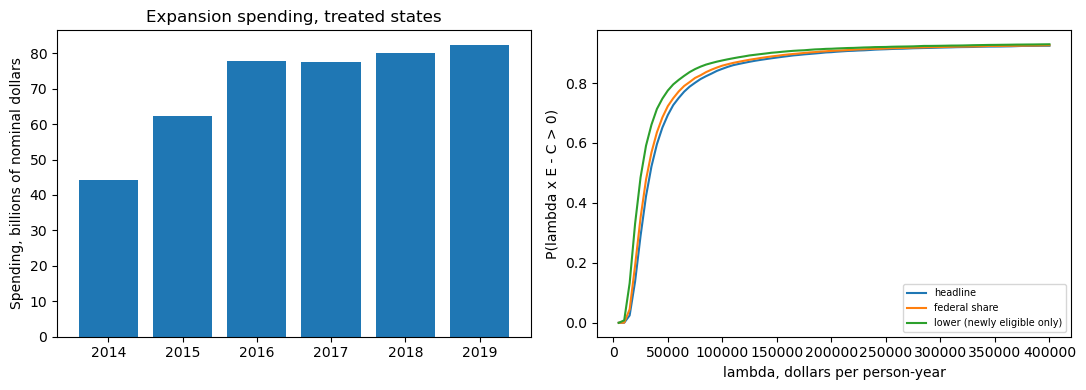

In [11]:
"""not pre-specified (added after review, 2026-10-25): the acceptability curve with the cost fixed at each definition, on a grid that reaches its ceiling."""
print(ADDED)
GRID = np.arange(5_000, 400_001, 5_000)
rows_c = []
p_pos = float(1 - stats.norm.cdf(0, person_years, person_years_se))
for name, value in totals.items():
    dc, de = cea.psa_normal(value, 0.0, person_years, person_years_se, correlation=0.0, n=N_DRAWS, seed=SEED)
    cur = cea.ceac(dc, de, GRID)
    at = {t: (int(GRID[cur.probability >= t][0]) if (cur.probability >= t).any() else None) for t in (0.5, 0.9)}
    rows_c.append({"cost fixed at": name, "lambda for P = 0.5": at[0.5], "lambda for P = 0.9": at[0.9], "P at the largest lambda": float(cur.probability[-1])})
print(pd.DataFrame(rows_c).to_string(index=False, float_format=lambda v: f"{v:,.3f}"))
print(f"each probability is P(lambda x E - C > 0) over {N_DRAWS:,} draws of the person-years E from a normal distribution with the stated mean and standard error "
      f"(seed {SEED}), with the cost C fixed; it can never exceed P(E > 0) = {p_pos:.3f}. lambda is a grid of dollars per person-year, not a willingness to pay anyone has stated.")
p_normal, p_t = float(stats.norm.cdf(0, person_years, person_years_se)), float(stats.t.cdf(0, df=fit_all.n_clusters - 1, loc=person_years, scale=person_years_se))
print(f"share of draws in which the effect is not positive: normal {p_normal:.4f}; with the t({fit_all.n_clusters - 1}) distribution the interval uses, {p_t:.4f}. "
      "The draws are a sampling approximation to the estimate's uncertainty, not a posterior.")
mid = 0.5 * (lower + upper)
dcm, dem = cea.psa_normal(mid, (upper - lower) / (2 * 1.96), person_years, person_years_se, correlation=0.0, n=N_DRAWS, seed=SEED)
cm = cea.ceac(dcm, dem, THRESHOLDS)
print(f"the plan's original curve drew the cost across the two spending definitions as a normal centred on their midpoint: it reaches {cm.probability[-1]:.3f} at "
      f"${int(THRESHOLDS[-1]):,}; the spread across two definitions is not sampling uncertainty, and the plan's grid stops there. Reporting changed after review; the settings did not.")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(table.index.astype(str), table["spending"] / 1e9, color="tab:blue")
axes[0].set_ylabel("Spending, billions of nominal dollars")
axes[0].set_title("Expansion spending, treated states")
for name, value in totals.items():
    dc, de = cea.psa_normal(value, 0.0, person_years, person_years_se, correlation=0.0, n=N_DRAWS, seed=SEED)
    axes[1].plot(GRID, cea.ceac(dc, de, GRID).probability, label=name)
axes[1].set_xlabel("lambda, dollars per person-year")
axes[1].set_ylabel("P(lambda x E - C > 0)")
axes[1].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [12]:
"""The decision rule from the plan, applied as written."""
print("Headline: NOT ESTIMABLE WITH USEFUL PRECISION." if not EXCLUDES_ZERO else "Headline: the effect interval excludes zero.")
rs_h, rs_n = SETS["headline"], SETS["lower (newly eligible only)"]
if not EXCLUDES_ZERO:
    print(f"The ratio is at least ${rs_h.positive_branch_lower:,.0f} per newly insured person-year (at least ${rs_n.positive_branch_lower:,.0f} on newly eligible spending), unbounded above.")
print(f"Spending ${headline / 1e9:,.1f} billion; effect {fit_all.coef:+.2f} pp [{fit_all.coef - t_crit * fit_all.se:+.2f}, {fit_all.coef + t_crit * fit_all.se:+.2f}]; {person_years / 1e6:,.2f} million person-years [{lo_e / 1e6:,.2f}, {hi_e / 1e6:,.2f}].")
print(f"Effect interval excludes zero (the plan's condition for reporting an interval): {EXCLUDES_ZERO}.")
print(f"Checks: reconciliation {RECONCILES}; no negative annual total {NO_NEGATIVE_YEAR}; sign agrees with C01 {SIGN_AGREES}.")
if not (RECONCILES and NO_NEGATIVE_YEAR and SIGN_AGREES):
    print("At least one check fails: the failure is reported here and the headline and the rules are unchanged.")

Headline: NOT ESTIMABLE WITH USEFUL PRECISION.
The ratio is at least $14,748 per newly insured person-year (at least $11,170 on newly eligible spending), unbounded above.
Spending $424.1 billion; effect -2.11 pp [-4.86, +0.64]; 12.49 million person-years [-3.78, 28.76].
Effect interval excludes zero (the plan's condition for reporting an interval): False.
Checks: reconciliation True; no negative annual total True; sign agrees with C01 True.


## Added after review (2026-10-25)

Everything from here to the Limitations is **not pre-specified (added after review, 2026-10-25)**. The plan's primary results are the ones above, with their
reporting corrected; none of these analyses replaces one.

In [13]:
"""not pre-specified (added after review, 2026-10-25): what the numerator contains, by state, and the claiming anomalies in the file."""
print(ADDED)
new_ = float(window["viii_newly_eligible_computable"].sum())
old_ = float(window["viii_not_newly_eligible_computable"].sum())
print(f"the plan's headline numerator, the VIII Group total computable, is ${totals['headline'] / 1e9:,.2f} billion: ${new_ / 1e9:,.2f} billion newly eligible and "
      f"${old_ / 1e9:,.2f} billion ({100 * old_ / totals['headline']:.1f}%) not newly eligible, which is mostly spending on adults already covered before 2014 under waivers, now paid at a different federal match.")
st = window.groupby("state")[["viii_computable", "viii_not_newly_eligible_computable"]].sum()
st["not newly eligible, % of state total"] = 100 * st["viii_not_newly_eligible_computable"] / st["viii_computable"]
top = st.sort_values("viii_not_newly_eligible_computable", ascending=False).head(6)
print((top.assign(**{"not newly eligible ($bn)": top["viii_not_newly_eligible_computable"] / 1e9})[["not newly eligible ($bn)", "not newly eligible, % of state total"]]).round(1).to_string())
print("the newly eligible spending is the closer measure of incremental spending and is shown as such, as a departure after review; the plan's headline computation is kept above for transparency.")
print("what each omission does to a cost per newly insured person-year: previously covered adults paid at the new match are in the numerator but not the denominator (the ratio is too high); "
      "'woodwork' enrollees, eligible before 2014 and enrolling after it, are paid under regular categories and so are missing from this numerator but present in the coverage gain (too low); "
      "crowd-out of other coverage is in the numerator and not in the gain (too high); the marketplace premium tax credits the expansion did or did not displace are in neither.")
cl = window.copy()
cl["anomaly"] = np.select(
    [cl["viii_newly_eligible_computable"] < cl["viii_newly_eligible_federal"], cl["viii_federal"] > cl["viii_computable"]],
    ["newly eligible total computable below its federal share", "federal share above total computable"], default="")
an = cl[cl["anomaly"] != ""].groupby(["state", "anomaly"]).size().rename("state-quarters")
print("claiming anomalies (rows where the file's own components disagree):")
print(an.to_string() if len(an) else "none in the window")
print("the file is cash-basis: prior-period adjustments reported after 2019 Q4 are outside the window, and adjustments inside it may relate to earlier quarters; negative quarterly cells are kept as reported.")

not pre-specified (added after review, 2026-10-25)
the plan's headline numerator, the VIII Group total computable, is $424.15 billion: $321.24 billion newly eligible and $102.91 billion (24.3%) not newly eligible, which is mostly spending on adults already covered before 2014 under waivers, now paid at a different federal match.
               not newly eligible ($bn)  not newly eligible, % of state total
state                                                                        
New York                           64.2                                  87.8
Arizona                            13.3                                  84.8
Massachusetts                      12.2                                 100.0
Illinois                            4.5                                  18.9
Delaware                            2.3                                  88.8
Connecticut                         1.4                                  13.8
the newly eligible spending is the closer mea

claiming anomalies (rows where the file's own components disagree):
state       anomaly                                                
Arkansas    federal share above total computable                       10
California  newly eligible total computable below its federal share     1
Delaware    federal share above total computable                        2
            newly eligible total computable below its federal share     5
Maryland    newly eligible total computable below its federal share     1
Minnesota   federal share above total computable                        1
Oregon      federal share above total computable                        3
the file is cash-basis: prior-period adjustments reported after 2019 Q4 are outside the window, and adjustments inside it may relate to earlier quarters; negative quarterly cells are kept as reported.


In [14]:
"""not pre-specified (added after review, 2026-10-25): the same estimate and ratio set without the states C01 sets aside for other coverage changes."""
print(ADDED)
CONTAMINATED = ["Wisconsin", "Delaware", "District of Columbia", "Massachusetts", "New York", "Vermont",
                "California", "Connecticut", "Minnesota", "New Jersey", "Washington"]
p_out = p_all[~p_all["state"].isin(CONTAMINATED)]
fit_out = estimate(p_out)
treated_out = [s for s in TREATED if s not in CONTAMINATED]
win_out = window[window["state"].isin(treated_out)]
py_out = -fit_out.coef / 100 * float(p_out[p_out["group"] == "treated"].groupby("year")["pop"].sum().loc[POST].sum())
py_out_se = fit_out.se / 100 * float(p_out[p_out["group"] == "treated"].groupby("year")["pop"].sum().loc[POST].sum())
t_out = float(stats.t.ppf(0.975, fit_out.n_clusters - 1))
lo_o, hi_o = py_out - t_out * py_out_se, py_out + t_out * py_out_se
print(f"without {len(CONTAMINATED)} states ({', '.join(CONTAMINATED)}): effect {fit_out.coef:+.3f} pp (SE {fit_out.se:.3f}, {fit_out.n_clusters} states), "
      f"95% interval [{fit_out.coef - t_out * fit_out.se:+.3f}, {fit_out.coef + t_out * fit_out.se:+.3f}]; {py_out / 1e6:,.2f} million person-years [{lo_o / 1e6:,.2f}, {hi_o / 1e6:,.2f}]")
for name, col in COLUMNS.items():
    spend_out = float(win_out[col].sum())
    rs = cea.ratio_set(spend_out, lo_o, hi_o)
    print(f"  {name:30s}: spending ${spend_out / 1e9:,.2f} billion; " + (f"ratio ${rs.lower:,.0f} to ${rs.upper:,.0f} per person-year" if rs.status == "bounded"
          else f"ratio at least ${rs.positive_branch_lower:,.0f}, unbounded above"))
print("New York, Massachusetts, Vermont, Delaware and the District of Columbia had broad adult coverage before 2014, so their gain is small and their spending is mostly not newly eligible; "
      "Wisconsin is a never-adopter that covers adults to 100% of the poverty level.")

not pre-specified (added after review, 2026-10-25)
without 11 states (Wisconsin, Delaware, District of Columbia, Massachusetts, New York, Vermont, California, Connecticut, Minnesota, New Jersey, Washington): effect -1.793 pp (SE 0.880, 24 states), 95% interval [-3.614, +0.028]; 4.40 million person-years [-0.07, 8.86]
  headline                      : spending $159.64 billion; ratio at least $18,016, unbounded above
  federal share                 : spending $150.70 billion; ratio at least $17,008, unbounded above
  lower (newly eligible only)   : spending $139.20 billion; ratio at least $15,710, unbounded above
New York, Massachusetts, Vermont, Delaware and the District of Columbia had broad adult coverage before 2014, so their gain is small and their spending is mostly not newly eligible; Wisconsin is a never-adopter that covers adults to 100% of the poverty level.


In [15]:
"""not pre-specified (added after review, 2026-10-25): how this estimate compares with C01's weighted sensitivity, a pre-period placebo, and a wild cluster bootstrap."""
print(ADDED)
cw = re.search(r"population-weighted ATT \(weights: 2013 population aged 35-64\):\s*([+-][\d.]+) pp \(SE ([\d.]+)\)", text)
print(f"this notebook is not C01's difference-in-differences: it is population-weighted, has a 2012-2013 pre-period, no lead test, and the small-sample factor with t({fit_all.n_clusters - 1}).")
print(f"the like-for-like comparison is C01's population-weighted sensitivity: ages 35-64, C01 {float(cw.group(1)):+.3f} pp (SE {float(cw.group(2)):.3f}); this notebook {fit_35.coef:+.3f} pp (SE {fit_35.se:.3f})")
early_ = p_all[p_all["year"] <= 2013].copy()
early_["D"] = ((early_["group"] == "treated") & (early_["year"] >= 2013)).astype(float)
fit_pl = estimate(early_)
print(f"pre-period placebo, treated states from 2013 against 2012: {fit_pl.coef:+.3f} pp (SE {fit_pl.se:.3f}), 95% interval [{fit_pl.coef - t_crit * fit_pl.se:+.3f}, {fit_pl.coef + t_crit * fit_pl.se:+.3f}]")
from krl_tutorials_data.methods import did
N_WILD = 9999
Xd = pd.concat([pd.get_dummies(p_all[c], prefix=c, drop_first=True) for c in ("state", "year")], axis=1).to_numpy(dtype=float)
Xf = np.column_stack([p_all["D"].to_numpy(), np.ones(len(p_all)), Xd])
yv, wv = p_all["rate"].to_numpy(), p_all["pop"].to_numpy()
gv = pd.factorize(p_all["state"])[0]
Gn = int(gv.max()) + 1

def wls_t(y_vec, X):
    """Weighted least squares and the clustered t statistic (small-sample factor) of the first column."""
    sw = np.sqrt(wv)
    Xw, yw = X * sw[:, None], y_vec * sw
    inv = np.linalg.inv(Xw.T @ Xw)
    beta = inv @ (Xw.T @ yw)
    resid = yw - Xw @ beta
    scores = np.zeros((Gn, X.shape[1]))
    np.add.at(scores, gv, Xw * resid[:, None])
    n_, k_ = X.shape
    vcov = (Gn / (Gn - 1)) * ((n_ - 1) / (n_ - k_)) * inv @ (scores.T @ scores) @ inv
    return float(beta[0]), float(beta[0] / np.sqrt(vcov[0, 0]))

b_o, t_o = wls_t(yv, Xf)
Xr = Xf[:, 1:]
beta_r = np.linalg.lstsq(Xr * np.sqrt(wv)[:, None], yv * np.sqrt(wv), rcond=None)[0]
fit_r, res_r = Xr @ beta_r, yv - Xr @ beta_r
mult = did.bootstrap_weights("webb", size=(N_WILD, Gn), seed=SEED)
t_star = np.array([wls_t(fit_r + mult[b][gv] * res_r, Xf)[1] for b in range(N_WILD)])
print(f"coefficient {b_o:+.3f} (t = {t_o:+.3f}); p-value: analytic t({Gn - 1}) {2 * stats.t.sf(abs(t_o), Gn - 1):.3f}; wild cluster bootstrap-t with Webb weights, {N_WILD} draws, seed {SEED}: {float(np.mean(np.abs(t_star) >= abs(t_o))):.3f}")

not pre-specified (added after review, 2026-10-25)
this notebook is not C01's difference-in-differences: it is population-weighted, has a 2012-2013 pre-period, no lead test, and the small-sample factor with t(34).
the like-for-like comparison is C01's population-weighted sensitivity: ages 35-64, C01 -1.562 pp (SE 1.251); this notebook -1.814 pp (SE 1.244)
pre-period placebo, treated states from 2013 against 2012: -0.110 pp (SE 0.344), 95% interval [-0.809, +0.588]


coefficient -2.112 (t = -1.560); p-value: analytic t(34) 0.128; wild cluster bootstrap-t with Webb weights, 9999 draws, seed 20261023: 0.177


## Limitations

- **The ratio is not estimable with useful precision.** The effect's 95% interval includes zero, so the cost per newly insured person-year has no finite upper
  limit; the ratio set printed above gives only a floor. The point ratio is arithmetic and is not a finding. Spending and the effect are reported separately
  for that reason.
- **The perspective is the public payer, on a cash basis, gross.** The cost is gross public spending in the CMS file, summed as reported. Prior-period
  adjustments reported after 2019 Q4 are outside the window, and adjustments inside it may relate to earlier quarters. Offsets that would lower the net cost are
  omitted (reduced uncompensated care, state savings, tax and employment effects), as is administrative cost, which would raise it. The marketplace premium tax
  credits that the expansion displaced or did not are in neither the numerator nor the effect.
- **The plan's numerator is not incremental spending.** The VIII Group total computable includes spending on adults who were covered before 2014 under waivers,
  now paid at a different federal match; the numerator cell prints how much, and for which states. Newly eligible spending is the closer measure of incremental
  spending and is reported beside the plan's figure, as a departure after review. Crowd-out of other coverage raises the numerator without raising the gain; woodwork
  enrollees (eligible before 2014, enrolling after) are paid under regular categories, so are missing from the numerator and present in the gain. Their directions
  differ, and none is netted out.
- **Claiming anomalies in the file.** The numerator cell prints state-quarters in which the file's own components disagree (a newly eligible total below its federal
  share, a federal share above its total). Nothing is repaired.
- **Nominal dollars from 2014 to 2019, summed, with no base year and no discounting** (discounting is E02). A figure in 2019 dollars was not computed.
- **One average effect for every year.** Coverage grew over 2014 and 2015, so a yearly split of this estimate would mislead; none is reported.
- **The acceptability curve is not a test of value.** With the cost fixed, P(lambda x E - C > 0) cannot exceed the probability that the effect is positive; the grid
  of lambda is not a willingness to pay anyone has stated and no external anchor is claimed. The draws are a normal sampling approximation, and the interval uses t.
- **Different populations.** The spending is for the expansion group as CMS defines it and the effect is for all adults 19 to 64; they overlap but are not identical.
- **The effect rests on parallel trends and is not C01's estimate.** It is C01's design on a different age range, population-weighted, with a 2012-2013 pre-period,
  no lead test, and the t distribution with the state count less one. The labelled comparison puts it beside C01's weighted sensitivity; C01's own result is
  borderline. The states C01 sets aside for other coverage changes, and Wisconsin, are dropped in a labelled sensitivity, which changes the effect.
- **Withheld cells.** The client withholds cells under 10 records; the retrieval step prints the share. Nothing was recoded or imputed.
- **Departures from the plan.** The plan was not edited. The first run stated that it did not depart from it. Measured against it, the report departs in these ways, all
  after review: the headline is not a point ratio; newly eligible spending is reported as the closer incremental measure; the acceptability curve fixes the cost at each
  definition on a wider grid; and the added analyses are labelled "not pre-specified" (the person-year table, the PUMS 35-64 estimate and the C01 comparison among them).
  The plan itself departs from "use C01's ATT" by re-estimating on ages 19 to 64, for the reason under Data Provenance, written before the cost table was built.

## Key Takeaways

1. A cost-effectiveness ratio is only as good as the match between the people the cost covers and the people the effect covers; here that meant
   re-estimating the effect for the whole expansion age range, and then asking whether the spending is incremental at all.
2. Government expenditure files carry negative adjustments, blanks, zeros, adjustments for other periods and spending that was not new; the notebook counts them and does not repair them.
3. Uncertainty comes from both sides of a ratio, and when the effect's interval includes zero the ratio has no finite upper limit. The notebook reports spending and the effect
   separately, a floor for the ratio, and the point ratio only as arithmetic, because a number from the middle of an interval that spans zero is not a finding.
4. Gross cost per newly insured person-year omits offsets that lower it and includes spending that was not incremental that raises it; the notebook names both and
   does not net them.
5. A probability computed with the cost fixed is bounded above by the probability that the effect is positive, whatever the threshold; a curve that stops short of that
   ceiling, or draws the cost across two definitions, is not showing what it appears to.

## Exercises

1. Replace the constant average effect with one effect per year from an event study. How does the cost per newly insured person in 2014 compare with 2019?
2. Use the federal share instead of the total and say whose cost per newly insured person that is.
3. Drop the treated state with the largest spending and re-estimate. Does the ratio move more through the cost or through the effect?
4. Add 20 per cent to the cost for administration. Which direction does it move the ratio, and does it change the conclusion about willingness to pay?

## References

- Drummond, M. F., Sculpher, M. J., Claxton, K., Stoddart, G. L., and Torrance, G. W. (2015). *Methods for the Economic Evaluation of Health Care Programmes* (4th ed.). Oxford University Press.
- Briggs, A., Claxton, K., and Sculpher, M. (2006). *Decision Modelling for Health Economic Evaluation*. Handbooks in Health Economic Evaluation. Oxford University Press.
- Fenwick, E., Claxton, K., and Sculpher, M. (2001). Representing uncertainty: the role of cost-effectiveness acceptability curves. *Health Economics*, 10(8), 779–787. https://doi.org/10.1002/hec.635
- Centers for Medicare & Medicaid Services. *Medicaid CMS-64 New Adult Group Expenditures* (version updated 17 February 2026), data.medicaid.gov. See `data/policy/medicaid/SOURCES.md`.
- U.S. Census Bureau. American Community Survey Public Use Microdata Sample documentation and data dictionaries, 2012–2019. https://www.census.gov/programs-surveys/acs/microdata/documentation.html